# 01 · Exploratory Data Analysis

**Goal.** Understand the training population (synthetic *normal* users) and the evaluation population (synthetic *fraud* users) well enough to (a) justify every preprocessing decision baked into the frozen model and (b) predict how an autoencoder will behave on this data *before* looking at model metrics.

**Data.** `data/non_fraud_night_1.csv.gz` (100,000 normal users, the exact file `night_4.h5` was trained on) and `data/fraud_night_1.csv` (2,500 fraud users, never seen in training). Both were generated with Faker + NumPy during the hackathon (`scripts/generate_synthetic_data.py` documents the generator).

> Constraint: the model is **not retrained**. EDA findings that would change the feature set are recorded as *recommendations for v2* rather than applied.

In [1]:
import sys, warnings; sys.path.insert(0, "../src"); warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from fraud_ae import config
pd.set_option("display.width", 160); pd.set_option("display.max_columns", 60)
SURFACE, INK2, NORMAL_C, FRAUD_C = "#fcfcfb", "#52514e", "#2a78d6", "#eb6834"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.color": "#e6e5e0", "font.size": 9})

In [2]:
normal = pd.read_csv(config.TRAIN_CSV)
fraud = pd.read_csv(config.FRAUD_CSV).drop(columns="Unnamed: 0")   # stray index column from to_csv()
print("normal", normal.shape, "| fraud", fraud.shape, "| same columns:", list(normal.columns) == list(fraud.columns))
normal.head(3)

normal (100000, 53) | fraud (2500, 53) | same columns: True


,user_id,age,gender,latitude,longitude,country,city,account_creation_date,account_type,subscription_plan,email_domain,phone_number_prefix,session_duration_avg,time_spent_per_action,number_of_sessions_per_day,device_type,browser_type,OS,most_active_hours,weekend_vs_weekday_activity_ratio,login_frequency_per_week,failed_login_attempts,password_reset_requests,total_transactions,avg_transaction_value,max_transaction_value,min_transaction_value,number_of_refunds,chargeback_ratio,number_of_failed_transactions,payment_methods_used,number_of_friends,number_of_messages_sent,number_of_posts,most_active_community,engagement_score,IP_address_diversity,VPN_or_Proxy_usage,device_switching_frequency,MAC_address_changes,number_of_sessions_from_unusual_locations,average_network_latency,packet_loss_rate,number_of_failed_captcha_attempts,multi_factor_authentication_enabled,account_suspension_count,fraud_report_count,password_change_frequency,device_trust_score,outlier_score,transaction_pattern_anomaly_score,time_series_anomaly_score,fraud_risk_score
0,8c5f9d0c-2d95-48bd-9f5d-a8e727a57336,40,Female,4.641717,178.005762,Palestinian Territory,North Brett,2021-09-06,Admin,Basic,yahoo.com,81,56.495090,6.761889,6,PC,Safari,Android,9,0.601437,6,1,0,315,228.519340,8074.925473,49.496523,3,0.022458,1,Crypto,199,645,32,Gaming,0.485915,6,0,2,1,1,203.800311,0.973601,1,0,0.0,0.0,3,0.831532,0.189822,0.037953,0.138798,0.050651
1,70d295c6-a8f7-484e-b9be-e7721d7dd0dd,60,Female,48.846542,-15.092113,Burundi,East Patriciamouth,2020-01-21,Business,Free,yahoo.com,44,21.608686,14.607827,2,PC,Firefox,Windows,2,1.441367,12,1,2,244,350.562387,569.006855,21.078474,3,0.016348,2,Credit Card,19,983,261,Finance,0.933780,3,0,1,2,0,254.386317,1.651819,1,0,0.0,0.0,1,0.716576,0.068291,0.086479,0.142337,0.078635
2,16646322-febd-4ea7-9d91-863bc6a79a50,66,Male,54.682439,122.739190,Bahrain,South Lukehaven,2020-06-22,Personal,Free,protonmail.com,44,5.053043,14.248726,1,Mobile,Safari,iOS,22,1.248630,11,2,2,146,20.914650,7105.291556,33.051526,3,0.007422,2,PayPal,128,917,113,Gaming,0.238118,2,0,4,0,1,30.162800,0.998864,0,0,0.0,0.0,1,0.977623,0.089734,0.127957,0.121302,0.008545


## 1. Schema, types, data quality

In [3]:
schema = pd.DataFrame({
    "dtype": normal.dtypes.astype(str),
    "n_unique": normal.nunique(),
    "missing": normal.isna().sum(),
    "example": normal.iloc[0],
})
schema

,dtype,n_unique,missing,example
user_id,str,100000,0,8c5f9d0c-2d95-48bd-9f5d-a8e727a57336
age,int64,52,0,40
gender,str,3,0,Female
latitude,float64,100000,0,4.641717
longitude,float64,100000,0,178.005762
country,str,243,0,Palestinian Territory
city,str,38144,0,North Brett
account_creation_date,str,1915,0,2021-09-06
account_type,str,3,0,Admin
subscription_plan,str,3,0,Basic


In [4]:
print("duplicate rows:", normal.duplicated().sum(), "| duplicate user_id:", normal.user_id.duplicated().sum())
print("constant columns in NORMAL data:", [c for c in normal if normal[c].nunique() == 1])
print("user_id overlap normal/fraud:", len(set(normal.user_id) & set(fraud.user_id)))

duplicate rows: 0 | duplicate user_id: 0
constant columns in NORMAL data: ['account_suspension_count', 'fraud_report_count']
user_id overlap normal/fraud: 0


**Findings**
- No missing values, no duplicates, no ID overlap between populations → no cleaning required; the data is clean *by construction*.
- `user_id` is a random UUID → pure identifier, carries no signal, **dropped** (ADR-002).
- `account_suspension_count` and `fraud_report_count` are **constant 0** in normal data. MinMaxScaler cannot scale a zero-range column (sklearn uses scale 1), so any non-zero value at inference lands far outside [0, 1]. This makes them near-perfect fraud detectors *and* a leakage risk: in a real bank these counters are written *after* fraud is confirmed.
- `phone_number_prefix` was parsed by pandas as an **integer** (`"+44"` → 44), so the model treats it as a magnitude, not a category. Frozen as-is.
- `account_creation_date` is a **string** with 1,915 distinct dates → label-encoded as if it were a category. Its natural form is a numeric *account age* (v2 recommendation).

## 2. Categorical features: cardinality and vocabulary overlap

In [5]:
cats = config.CATEGORICAL_COLS
rows = []
for c in cats:
    nv, fv = set(normal[c].astype(str)), set(fraud[c].astype(str))
    rows.append({"feature": c, "card_normal": len(nv), "card_fraud": len(fv),
                 "fraud_values_unseen_in_train": f"{(~fraud[c].astype(str).isin(nv)).mean():.1%}",
                 "fraud_only_values": sorted(fv - nv)[:4] if len(fv - nv) < 50 else "(many)"})
pd.DataFrame(rows).set_index("feature")

,card_normal,card_fraud,fraud_values_unseen_in_train,fraud_only_values
feature,,,,
gender,3,3,0.0%,[]
country,243,243,0.0%,[]
city,38144,2309,22.2%,(many)
account_creation_date,1915,88,0.0%,[]
account_type,3,3,0.0%,[]
subscription_plan,3,3,0.0%,[]
email_domain,4,4,72.4%,"[disposable.com, randommail.net, tempmail.com]"
device_type,3,3,0.0%,[]
browser_type,5,4,49.5%,"[BotBrowser, Unknown]"


**Findings**
- Low-cardinality categoricals (≤ 5 levels) are fine for any encoding. `city` (38k levels) and `country` (243) are high-cardinality and, in this generator, **independent of latitude/longitude** (Faker draws them separately) → they are noise.
- Several fraud categories never occur in training (`tempmail.com`, `BotBrowser`, `Scam`, `Stolen Card`, …): 72% of fraud rows have an unseen `email_domain`, 50% an unseen `browser_type`. The frozen pipeline maps them to `-1` (the hackathon's own `encode_with_fallback` convention, ADR-004). After MinMax scaling that is only slightly below 0, a **weak** signal: label encoding compresses "never seen before" into a small numeric nudge. One-hot plus an explicit `is_unseen` flag would make novelty loud (v2).

## 3. Numeric features: distributions, normal vs fraud

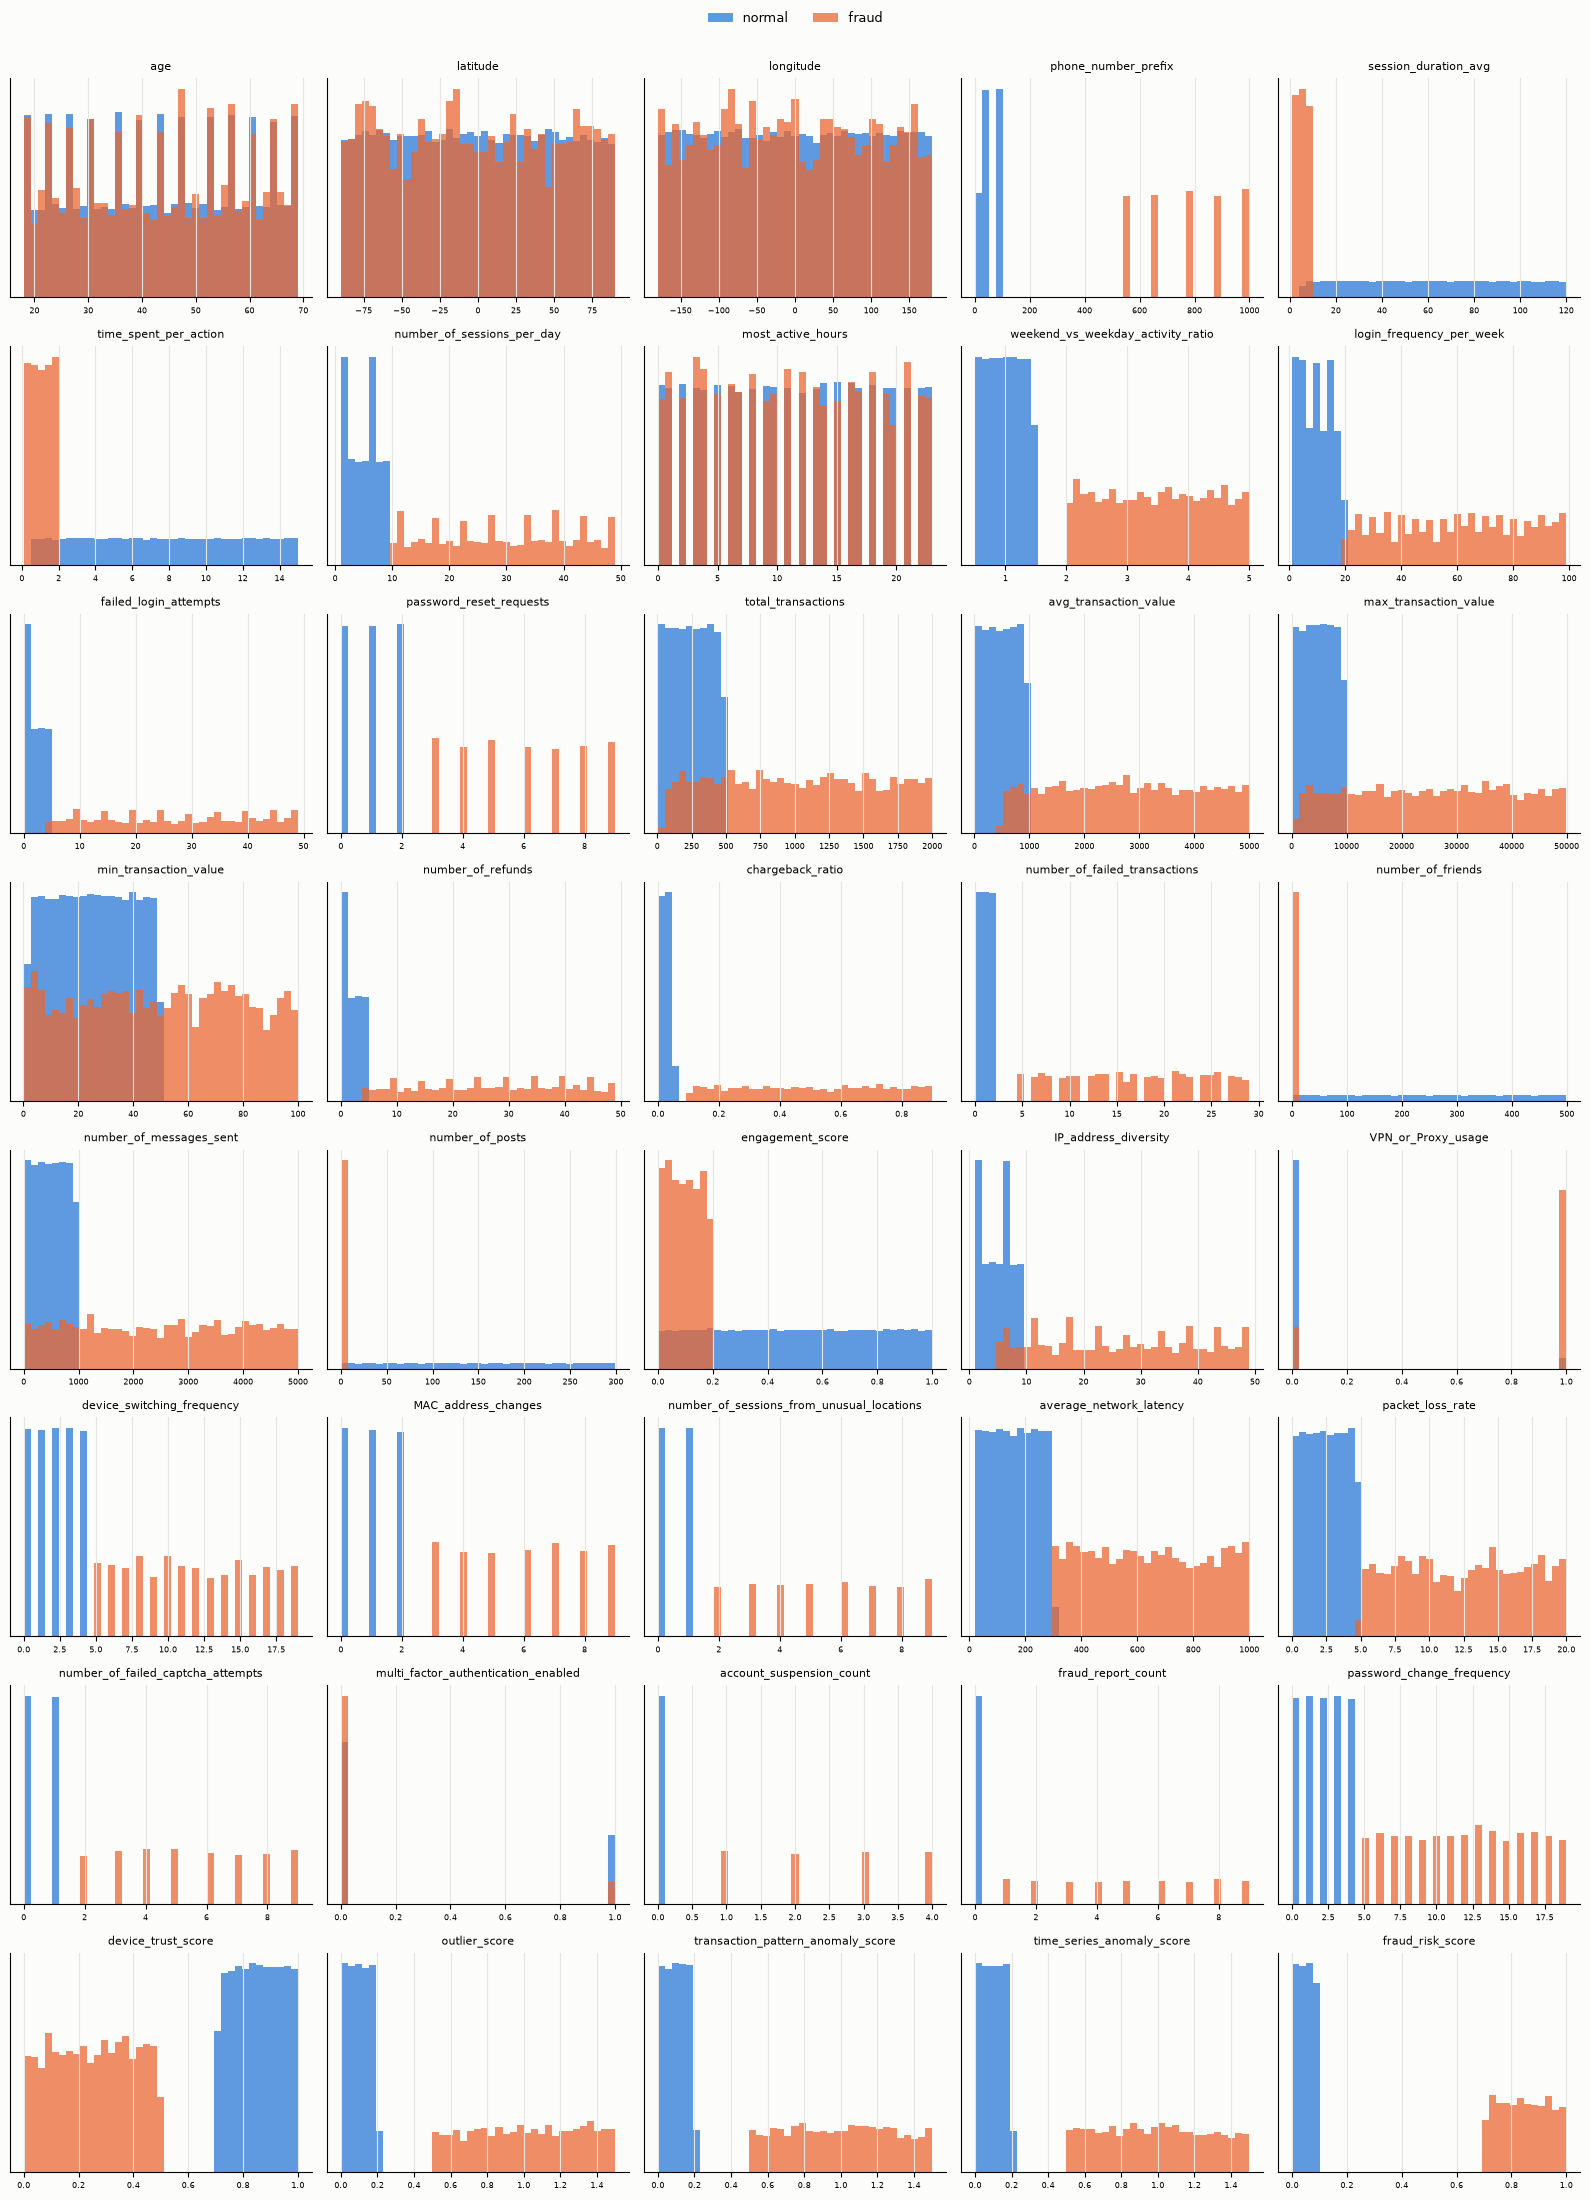

In [6]:
num = [c for c in normal.columns if c not in cats + ["user_id"]]
fig, axes = plt.subplots(8, 5, figsize=(16, 22)); axes = axes.ravel()
for ax, c in zip(axes, num):
    lo, hi = min(normal[c].min(), fraud[c].min()), max(normal[c].max(), fraud[c].max())
    bins = np.linspace(lo, hi if hi > lo else lo + 1, 40)
    ax.hist(normal[c], bins=bins, density=True, color=NORMAL_C, alpha=.75)
    ax.hist(fraud[c], bins=bins, density=True, color=FRAUD_C, alpha=.75)
    ax.set_title(c, fontsize=8); ax.tick_params(labelsize=6); ax.set_yticks([])
for ax in axes[len(num):]: ax.axis("off")
fig.legend(["normal", "fraud"], loc="upper center", ncol=2, frameon=False)
fig.tight_layout(rect=(0, 0, 1, .98)); fig.savefig("../docs/figures/eda_numeric_distributions.png", dpi=110); plt.show()

Every numeric feature is drawn from an independent **uniform** distribution (or integer-uniform / Bernoulli). Real behavioural data is skewed, heavy-tailed and correlated; this is the single biggest gap between this project and production, and it is why the metrics in notebook 02 are near-perfect.

In [7]:
# How separable is each feature on its own? share of fraud rows outside the normal [min, max] range
sep = pd.Series({c: ((fraud[c] < normal[c].min()) | (fraud[c] > normal[c].max())).mean() for c in num}).sort_values(ascending=False)
sep.to_frame("fraud_rows_outside_normal_range").style.format("{:.1%}").bar(color="#eb683455", vmin=0, vmax=1)

,fraud_rows_outside_normal_range
phone_number_prefix,100.0%
number_of_sessions_per_day,100.0%
number_of_failed_transactions,100.0%
chargeback_ratio,100.0%
password_reset_requests,100.0%
failed_login_attempts,100.0%
login_frequency_per_week,100.0%
weekend_vs_weekday_activity_ratio,100.0%
time_series_anomaly_score,100.0%
transaction_pattern_anomaly_score,100.0%


**Findings**
- **23 of 40** numeric features place **every** fraud row outside the range ever seen in training (29 place at least half): the populations were generated from *disjoint* intervals (e.g. `chargeback_ratio` normal ∈ [0, 0.05], fraud ∈ [0.1, 0.9]). Any detector, even a per-feature range check, separates them.
- Demographics (`age`, `gender`, `latitude`, `longitude`, `OS`, `most_active_hours`) are **identically distributed** in both populations: zero signal, by design.
- The four `*_score` columns are *outputs of other models* (`fraud_risk_score` normal ∈ [0, 0.1], fraud ∈ [0.7, 1]). Using them as inputs is circular; notebook 02 shows the model still catches 100% of fraud without them.

## 4. Correlation structure (what can the autoencoder actually learn?)

max |off-diagonal correlation| in normal data: 0.0112


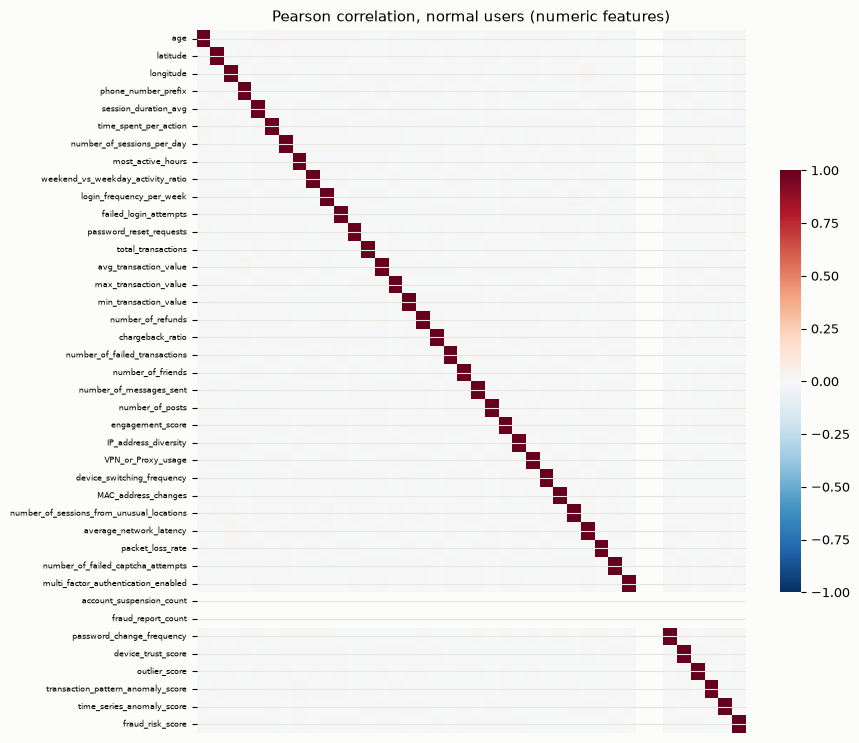

In [8]:
enc = normal[num].copy()
corr = enc.corr()
off = corr.where(~np.eye(len(corr), dtype=bool)).abs()
print(f"max |off-diagonal correlation| in normal data: {off.max().max():.4f}")
fig, ax = plt.subplots(figsize=(9, 7.5))
sns.heatmap(corr, cmap="RdBu_r", center=0, vmin=-1, vmax=1, ax=ax, xticklabels=False, yticklabels=True, cbar_kws={"shrink": .6})
ax.tick_params(labelsize=6); ax.set_title("Pearson correlation, normal users (numeric features)")
fig.tight_layout(); fig.savefig("../docs/figures/eda_correlation.png", dpi=110); plt.show()

**This is the key modelling insight.** Correlations are ≈ 0 everywhere, even where the real world would couple them (`max_transaction_value` vs `avg_transaction_value`, `total_transactions` vs `number_of_refunds`). An autoencoder detects anomalies by learning the *joint* structure of normal data; when features are independent there is no structure to compress, so a 32-unit bottleneck cannot reconstruct 52 independent uniforms well. Expected consequences, confirmed in notebook 02:

1. The normal reconstruction error stays relatively high (MSE ≈ 0.033; training loss plateaued at ≈ 0.040 in the original log).
2. What the model *does* learn is each feature's **range**, so it behaves like a smooth multi-feature range check, which is exactly what this data rewards.
3. Fraud that stays inside every normal range would be invisible. That data does not exist here, so the reported recall is an upper bound.

## 5. Class balance and evaluation implications

In [9]:
print(f"fraud share if pooled: {len(fraud) / (len(fraud) + len(normal)):.2%}")
print("account_creation_date range  normal:", normal.account_creation_date.min(), "→", normal.account_creation_date.max(),
      "| fraud:", fraud.account_creation_date.min(), "→", fraud.account_creation_date.max())

fraud share if pooled: 2.44%
account_creation_date range  normal: 2020-01-01 → 2025-03-29 | fraud: 2025-01-01 → 2025-03-29


- Pooled prevalence is 2.4%. The evaluation set (10k held-out normals + 2.5k fraud) is 20% fraud, so raw precision on it is inflated. Notebook 02 therefore also reports precision re-weighted to an assumed **1% prevalence**.
- Fraud accounts were all created "this year" (2025) vs. "this decade" for normals: a real-world-plausible signal (new accounts are riskier) that the date-as-category encoding mostly wastes.

## 6. Summary → decisions

| EDA finding | Decision in the frozen pipeline | v2 recommendation (requires retraining) |
|---|---|---|
| `user_id` is a random UUID | drop | same |
| Constant-zero counters in normal data | keep (model was trained with them) | drop: post-hoc labels, leakage |
| `*_score` columns are other models' outputs | keep, but show recall without them | drop |
| `account_creation_date` as string | label-encode (frozen) | `account_age_days` numeric |
| `city`/`country` high-card, independent of lat/long | label-encode (frozen) | drop or frequency-encode |
| Unseen fraud categories | map to −1, report unseen-rate per request | one-hot + `is_unseen` flag |
| Independent uniform features | — | collect or simulate correlated behaviour; otherwise prefer simple range/IsolationForest baselines |
| Disjoint feature ranges | report results as an upper bound | build a *hard* fraud set that overlaps normal ranges |